# Assignment 2: Classification using the Bayes Decision Rule and Support Vector Machines
## TTT4185 Machine learning for Speech technology

This assignment assumes that the student has knowledge about the Bayes Decision Rule, maximum likelihood estimation and support vector machines.

In this assignment we will use `scikit-learn` (http://scikit-learn.org/stable/), which is a powerful and very popular Python toolkit for data analysis and machine learning, and `pandas` (https://pandas.pydata.org), which implements the all-powerful `DataFrame`.

We will also be using a small database of phonemes, where each phoneme is represented by the four first formant positions ("F1"-"F4") and their corresponding bandwidths ("B1"-"B4"). All numbers are in kHz. In addition, the speaker ID and the gender of the speaker are given for each phoneme.

In [1]:
# this will fetch the Train.csv and Test.csv so you do not need to manually upload them. Just run this block for each session

! wget https://giampies.folk.ntnu.no/ttt4185/assignment2/Train.csv
! wget https://giampies.folk.ntnu.no/ttt4185/assignment2/Test.csv

--2026-10-18 22:47:09--  https://giampies.folk.ntnu.no/ttt4185/assignment2/Train.csv
Resolving giampies.folk.ntnu.no (giampies.folk.ntnu.no)... 2001:700:305:8008::205, 129.241.121.205
Connecting to giampies.folk.ntnu.no (giampies.folk.ntnu.no)|2001:700:305:8008::205|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2042638 (1.9M) [text/csv]
Saving to: ‘Train.csv.1’

Train.csv.1         100%[===================>]   1.95M  10.3MB/s    in 0.2s    

2026-10-18 22:47:09 (10.3 MB/s) - ‘Train.csv.1’ saved [2042638/2042638]

--2026-10-18 22:47:10--  https://giampies.folk.ntnu.no/ttt4185/assignment2/Test.csv
Resolving giampies.folk.ntnu.no (giampies.folk.ntnu.no)... 2001:700:305:8008::205, 129.241.121.205
Connecting to giampies.folk.ntnu.no (giampies.folk.ntnu.no)|2001:700:305:8008::205|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1158457 (1.1M) [text/csv]
Saving to: ‘Test.csv.1’

Test.csv.1          100%[===================>]   1.10M  1.87MB

## Problem 1: Maximum Likelihood

In this problem we will use the Bayes decision rule to classify vowels based on their formants. The formants have been extracted from the open database `VTR Formants database` (http://www.seas.ucla.edu/spapl/VTRFormants.html) created by Microsoft and UCLA.



### Task 1

Download the files `Train.csv` and `Test.csv` from Blackboard then upload them to your Colab workspace. You can load them into a `pandas` dataframe using the command `pd.read_csv`. Using the training data, create a single scatter plot of "F1" vs "F2" for the three vowels
- "ae" as in "bat"
- "ey" as in "bait"
- "ux" as in "boot"

Just eyeing the plots, discuss which classes will be hardest to classify correctly.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load data
train = pd.read_csv("Data/Train.csv")
test = pd.read_csv("Data/Test.csv")

# Extract vowels
train = train[train['Phoneme'].isin(['ae', 'ey', 'ux'])]
test = test[test['Phoneme'].isin(['ae', 'ey', 'ux'])]
y_train = train['Phoneme']
y_test = test['Phoneme']
y_train_values = y_train.values
y_test_values = y_test.values

# Plotting here

trainvow_ae = train[train['Phoneme'] == 'ae']
trainvow_ey = train[train['Phoneme'] == 'ey']
trainvow_ux = train[train['Phoneme'] == 'ux']

train_vow = [trainvow_ae, trainvow_ey, trainvow_ux]
train_str = ['ae', 'ey', 'ux']
labels_raw = train['Phoneme'].unique()
labels = [str(label) for label in labels_raw]
labels = sorted(labels)

colors = {
    'ae': 'red',
    'ey': 'blue',
    'ux': 'green'
}

# Create the F1/F2 grid
F1_values = np.linspace(train['F1'].min(), train['F1'].max(), 200)
F2_values = np.linspace(train['F2'].min(), train['F2'].max(), 200)

F1_grid, F2_grid = np.meshgrid(F1_values, F2_values)

grid_points = np.column_stack([
    F1_grid.ravel(), F2_grid.ravel()
])

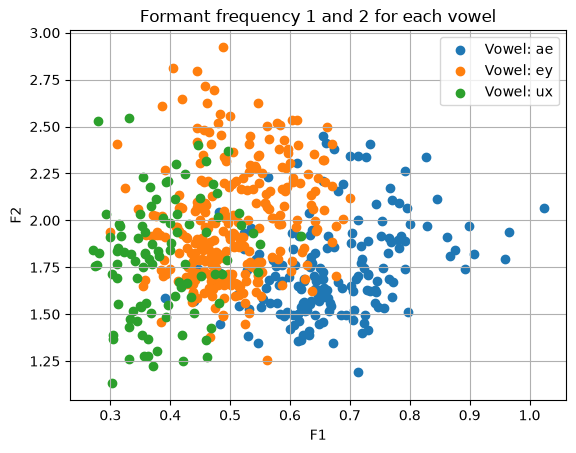

In [3]:
for data, name in zip(train_vow, train_str):
    plt.scatter(data['F1'], data['F2'], label=f"Vowel: {name}")
model_params = {label: {} for label in labels}

plt.xlabel("F1")
plt.ylabel("F2")
plt.legend()
plt.grid()
plt.title("Formant frequency 1 and 2 for each vowel")
plt.show()

F1 correlates to mouth openness and F2 corresponds to "frontness" to "backness". What we then see is that "ae" in "Bat" pertrudes far right as it is a vowel produces far back in the mouth.
Similarly, "ux" is far left, as it is produces far in the fornt of the mouth.

As a result we see the vowel "ey" is located in the midst of the two, and as it has overlaps with each of them, I would assume that it will be the hardest to classify correctly.



### Task 2

 Use the Bayes Decision Rule to create a classifier for the phonemes 'ae', 'ey' and 'ux' under the following constraints:
- The feature vector $x$ contains the first two formants, "F1" and "F2".
- The distribution of $x$ given a phoneme $c$, $P(x|c)$, is Gaussian.
- Use the maximum likelihood estimator to estimate the model parameters.

In [4]:
# The three classes we want to classify
vowels = ['ae', 'ey', 'ux']

# Store the model parameters for each class
model = {}

for v in vowels:
    # Keep only training examples belonging to this vowel
    data = train[train['Phoneme'] == v][['F1', 'F2']].values

    # Estimate the mean and covariance using maximum likelihood
    mean = np.mean(data, axis=0)
    cov = np.cov(data, rowvar=False, bias=True)

    # Estimate the prior probability of this vowel
    prior = len(data) / len(train)

    # Save the parameters
    model[v] = {
        'mean': mean,
        'cov': cov,
        'prior': prior
    }
# Extract F1 and F2 from the test data
X_test = test[['F1', 'F2']].values

# Store the predicted classes
predictions = []

for x in X_test:
    # Calculate the log posterior score for each vowel
    scores = []

    for v in vowels:
        mean = model[v]['mean']
        cov = model[v]['cov']
        prior = model[v]['prior']

        # Gaussian likelihood multiplied by the prior
        score = multivariate_normal.logpdf(x, mean=mean, cov=cov)
        score += np.log(prior)

        scores.append(score)

    # Select the vowel with the highest score
    predictions.append(vowels[np.argmax(scores)])

for v in vowels:
    print(f"\n\nVowel: {v}")
    print("\nMean:")
    print(model[v]['mean'])

    print("Cov:")
    print(model[v]['cov'])

    print("Prior probability:")
    print(model[v]['prior'])



Vowel: ae

Mean:
[0.6698604 1.7423804]
Cov:
[[0.0105471  0.00754655]
 [0.00754655 0.0628065 ]]
Prior probability:
0.31115107913669066


Vowel: ey

Mean:
[0.50455191 1.97840056]
Cov:
[[0.00600115 0.00385609]
 [0.00385609 0.08754451]]
Prior probability:
0.5089928057553957


Vowel: ux

Mean:
[0.38738423 1.78944744]
Cov:
[[0.00488957 0.00300388]
 [0.00300388 0.09384261]]
Prior probability:
0.17985611510791366


Bayes decision rule $P(c|x) = \frac{(P(x|c) P(c))}{P(x)}$

Prior probability:
$P(c)$ - how common a vowel is before considering its formants

Likelyhood of a vowel:
$P(x|c)$

Posterior probability:
$P(c|x)$ - what we calculate

### Task 3

To visualize the classes models and the classifier created in Task 2, plot the contours for each Gaussian distribution in the model. That is, the class conditional likelihoods $P(x|c)$, by using the following function.

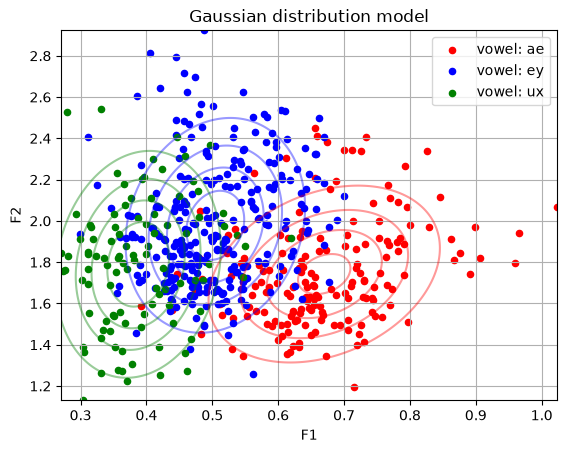

In [5]:
# 1. Create a grid of F1 and F2 values
F1_values = np.linspace(train['F1'].min(), train['F1'].max(), 200)
F2_values = np.linspace(train['F2'].min(), train['F2'].max(), 200)

F1_grid, F2_grid = np.meshgrid(F1_values, F2_values)

# Combine the grid into coordinate pairs
grid_points = np.column_stack([
    F1_grid.ravel(),
    F2_grid.ravel()
])

vow_colors = {
    'ae': 'r',
    'ey': 'b',
    'ux': 'g'
}

scores = []

# 2. Plot the training data
for v in vowels:
    data = train[train['Phoneme'] == v]
    plt.scatter(data['F1'], data['F2'], s=20, label=f"vowel: {v}", color=vow_colors[v])

# 3. Plot the Gaussian contours for each vowel
for v in vowels:

    # Get the estimated Gaussian parameters
    mean = model[v]['mean']
    cov = model[v]['cov']

    # Calculate the Gaussian likelihood at each grid point
    likelihood = multivariate_normal.pdf(
        grid_points, mean=mean, cov=cov
    )

    # Reshape the likelihood values to match the grid
    likelihood = likelihood.reshape(F1_grid.shape)

    posterior = likelihood * prior
    scores.append(posterior)

    # Draw the contour lines
    plt.contour(F1_grid, F2_grid, likelihood, levels=5, colors=vow_colors[v], alpha = 0.4)

# 4. Label and display the plot
plt.xlabel('F1')
plt.ylabel('F2')
plt.title('Gaussian distribution model')
plt.legend()
plt.grid()
plt.show()

Contours closer to epicenter represent a larger likelyhood of that specific coloured vowel to be the case.

#### Optional

*Try:* Plot the decision regions for the Bayesian classifier. Tips: Calculate the posterior for each class, use the `numpy.argmax` function to get the decision regions, and `matplotlib.pyplot.contourf` to plot them.

In [6]:
def plot_decision_regions(train, model, classes):

    # Calculate log posterior scores for each class
    scores = []
    for c in classes:
        likelihood = multivariate_normal.pdf(
            grid_points,
            mean=model[c]['mean'],
            cov=model[c]['cov']
        )

        scores.append(likelihood * model[c]['prior'])

    scores = np.array(scores)

    # Assign each grid point to the class with the highest score
    regions = np.argmax(scores, axis=0)
    regions = regions.reshape(F1_grid.shape)

    # Plot the decision regions
    plt.figure(figsize=(10, 7))

    plt.contourf(F1_grid, F2_grid, regions, levels=np.arange(len(classes) + 1) - 0.5, colors=[colors[c] for c in classes], alpha=0.15
    )

    # Plot the training observations and Gaussian contours
    for c in classes:

        data = train[train['Phoneme'] == c]

        plt.scatter(data['F1'], data['F2'], color=colors[c], s=10, alpha=0.5, label=c)

        likelihood = multivariate_normal.pdf(grid_points, mean=model[c]['mean'], cov=model[c]['cov']).reshape(F1_grid.shape)

        plt.contour(F1_grid, F2_grid, likelihood, levels=5, colors=[colors[c]])

    plt.xlabel('F1')
    plt.ylabel('F2')
    plt.title('Gaussian Contours and Bayesian Decision Regions')
    plt.legend()
    plt.grid(True)
    plt.show()


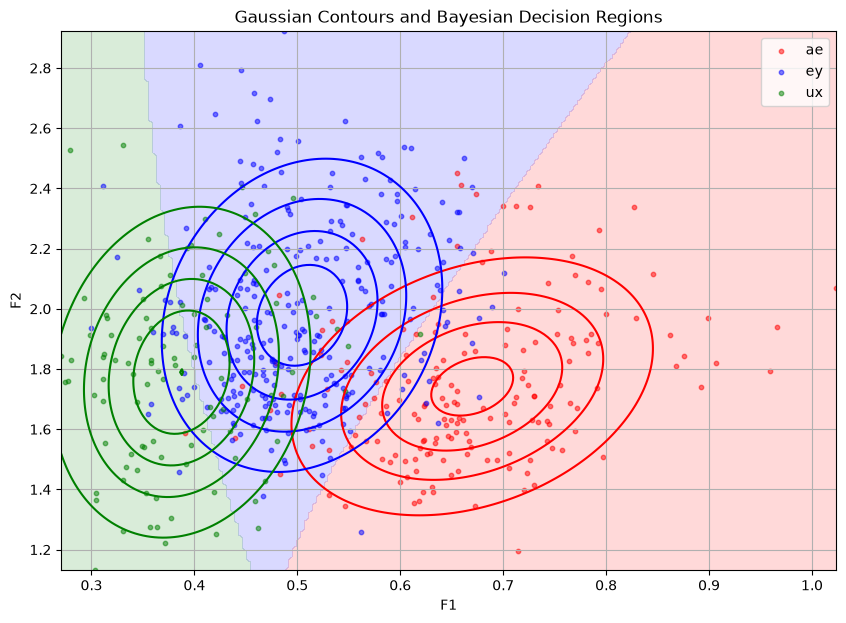

In [7]:
plot_decision_regions(train, model, vowels)

### Task 4

Test your classifier on the 'ae', 'ey' and 'ux' phonemes from the test set and present your results in a _confusion matrix_. That is, a table where you see how many times 'ae' was correctly classified, how many times it was wrongly classified as 'ey' and so on.

In [8]:
def train_model(train, classes):
    model = {}
    for c in classes:
        data = train[train['Phoneme'] == c][['F1', 'F2']].values
        mean = np.mean(data, axis=0)
        cov = np.cov(data, rowvar=False, bias=True)
        prior = len(data) / len(train)
        model[c] = {
            'mean': mean,
            'cov': cov,
            'prior': prior
        }
    return model

def predict_vowel(X, model, classes):
    predictions = []
    for x in X:
        scores = []
        for c in classes:
            mean = model[c]['mean']
            cov = model[c]['cov']
            prior = model[c]['prior']
            # Log likelihood plus log prior
            score = multivariate_normal.logpdf(
                x, mean=mean, cov=cov
            )
            score += np.log(prior)

            scores.append(score)
        predictions.append(classes[np.argmax(scores)])
    return np.array(predictions)


def print_parameters(model, classes):
    for c in classes:
        print(f"\nVowel: {c}")
        print("Mean:", model[c]['mean'])
        print("Covariance matrix:\n", model[c]['cov'])
        print("Prior probability:", model[c]['prior'])

def evaluate_model(y_true, predictions, classes):

    cm = confusion_matrix(
        y_true, predictions, labels=classes
    )

    print("Confusion Matrix:")
    print(pd.DataFrame(
        cm,
        index=[f"Actual {c}" for c in classes],
        columns=[f"Predicted {c}" for c in classes]
    ))

    print("\nAccuracy:", accuracy_score(y_true, predictions))

def plot_confusion_matrix(y_true, predictions, classes):

    cm = confusion_matrix(y_true, predictions, labels=classes)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=classes)

    disp.plot()
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()





Vowel: ae
Mean: [0.67865079 1.77850617]
Covariance matrix:
 [[0.00916535 0.00107953]
 [0.00107953 0.05014315]]
Prior probability: 0.3874538745387454

Vowel: ey
Mean: [0.52320281 1.95239566]
Covariance matrix:
 [[0.0062097  0.00403326]
 [0.00403326 0.04892499]]
Prior probability: 0.42066420664206644

Vowel: ux
Mean: [0.41520555 1.80416895]
Covariance matrix:
 [[0.00663015 0.00168941]
 [0.00168941 0.07946351]]
Prior probability: 0.1918819188191882
Confusion Matrix:
           Predicted ae  Predicted ey  Predicted ux
Actual ae            81            23             1
Actual ey            13            93             8
Actual ux             1            22            29

Accuracy: 0.7490774907749077


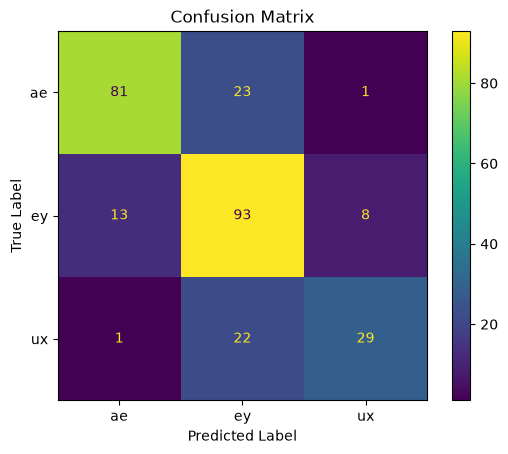

In [ ]:
# Load data
train = pd.read_csv("Data/Train.csv")
test = pd.read_csv("Data/Test.csv")

# Choose the classes
classes = ['ae', 'ey', 'ux']

# Filter the datasets
train = train[train['Phoneme'].isin(classes)].copy()
test = test[test['Phoneme'].isin(classes)].copy()

# Train the model
model = train_model(test, classes)

# Print the estimated parameters
print_parameters(model, classes)

# Predict the test labels
X_test = test[['F1', 'F2']].values
y_test = test['Phoneme'].values

predictions = predict_vowel(X_test, model, classes)

labels_raw = train['Phoneme'].unique()              # because task 3 renames labels to something else
labels = [str(label) for label in labels_raw]
labels = sorted(labels)

# Evaluate the classifier
evaluate_model(y_test, predictions, classes)

# Plot the confusion matrix
plot_confusion_matrix(y_test, predictions, classes)


### Task 5

Extend your classifier to include the features "F1"-"F4" and compare the results with those in Task 4.

_For this task I reiterate the train_model(train, classes,features) to include an undefined amount of features, so that the model can be trained on data containing an increased amount of variables_

In [10]:
def train_model(train, vowels, features):

    model = {}

    for v in vowels:
        data = train[train['Phoneme'] == v][features].values

        mean = np.mean(data, axis=0)
        cov = np.cov(data, rowvar=False, bias=True)
        prior = len(data) / len(train)

        model[v] = {
            'mean': mean,
            'cov': cov,
            'prior': prior
        }

    return model

features = ['F1', 'F2', 'F3', 'F4']
data = train[train['Phoneme'] == v][features].values


Vowel: ae
Mean: [0.6698604  1.7423804  2.59929494 3.95421828]
Covariance matrix:
 [[0.0105471  0.00754655 0.01118487 0.01353269]
 [0.00754655 0.0628065  0.04798571 0.04673581]
 [0.01118487 0.04798571 0.06974166 0.05271462]
 [0.01353269 0.04673581 0.05271462 0.13707   ]]
Prior probability: 0.31115107913669066

Vowel: ey
Mean: [0.50455191 1.97840056 2.6682647  3.93370995]
Covariance matrix:
 [[0.00600115 0.00385609 0.00741741 0.00769848]
 [0.00385609 0.08754451 0.07434405 0.06253448]
 [0.00741741 0.07434405 0.08477129 0.06289531]
 [0.00769848 0.06253448 0.06289531 0.12678471]]
Prior probability: 0.5089928057553957

Vowel: ux
Mean: [0.38738423 1.78944744 2.51461378 3.8702682 ]
Covariance matrix:
 [[0.00488957 0.00300388 0.00555523 0.0075836 ]
 [0.00300388 0.09384261 0.05596541 0.04586166]
 [0.00555523 0.05596541 0.06678    0.04373613]
 [0.0075836  0.04586166 0.04373613 0.10432254]]
Prior probability: 0.17985611510791366
Confusion Matrix:
           Predicted ae  Predicted ey  Predicted u

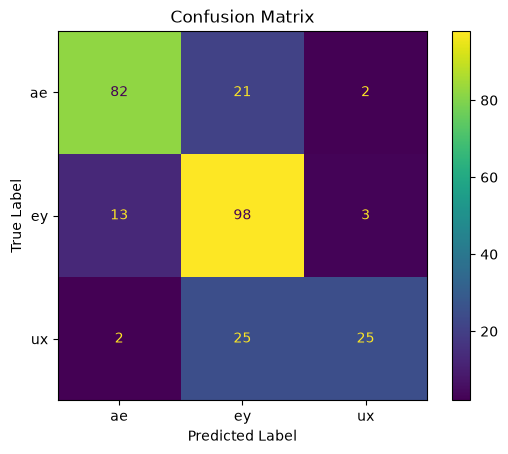

In [11]:
# Choose the classes and features
vowels = ['ae', 'ey', 'ux']
features = ['F1', 'F2', 'F3', 'F4']

# Train the model using four features
model = train_model(train, vowels, features)

# Print estimated parameters
print_parameters(model, vowels)

# Predict the test labels
X_test = test[features].values
y_test = test['Phoneme'].values

predictions = predict_vowel(X_test, model, vowels)

# Evaluate the classifier
evaluate_model(y_test, predictions, vowels)

# Plot the confusion matrix
plot_confusion_matrix(y_test, predictions, vowels)

### Task 6

Finally use all available information "F1"-"F4" and "B1-B4". How does the performance of this classifier compare with the simpler classifiers using fewer features?

_Using the refurbished train_model-function from task 5, i include the phonemes B1-B4_

Confusion Matrix:
           Predicted ae  Predicted ey  Predicted ux
Actual ae            82            23             0
Actual ey            13            90            11
Actual ux             3            28            21

Accuracy: 0.7121771217712177


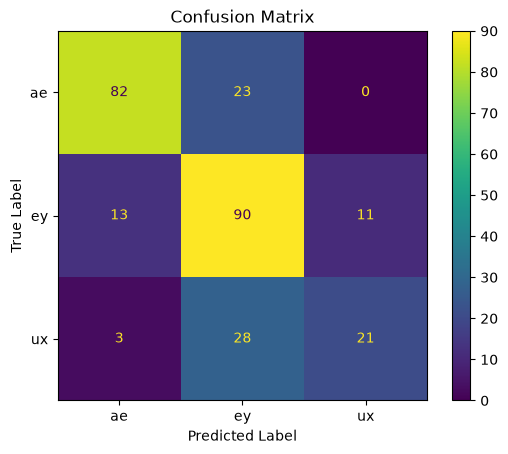

In [12]:
features = ['F1', 'F2', 'F3', 'F4', 'B1', 'B2', 'B3', 'B4']
model = train_model(train, classes, features)

#test data
X_test = test[features].values
y_test = test['Phoneme'].values

predictions = predict_vowel(X_test, model, classes)

evaluate_model(y_test, predictions, classes)
plot_confusion_matrix(y_test, predictions, classes)

_B1–B4 may not provide enough new information to distinguish these vowels beyond what F1–F4 provide. In addtition; more parameters to estimate requires a lot mot data to be able to predict correctly._ 

_We see that the overall accuracy is reduced from ≈75% to about ≈71%, because the quality of the classification between 'ey' and 'ux' worsens._

### Task 7

To better understand how important each feature is to the model, we will now perform permutation feature importance (https://scikit-learn.org/stable/modules/permutation_importance.html). The idea is that for each feature we will randomly shuffle the values and the ask the trained model to predict using this shuffled data. We can then observe how the performance degregates as each feature is shuffled.

For the model, take one of the 8 features (four formants and four bandwidths), shuffle and evaluate it 10 times. Repeat this process for each feature. Which feature has the biggest impact on model performance? Does this align with your knowlege of formants?

Below we've provided a sample function to get you started

Baseline accuracy: 71.22%

Permutation importance over 10 repetitions:
Feature  Mean shuffled accuracy  Accuracy drop  Importance (%)  Std. deviation
     F1                  0.4664         0.2458         24.5756          0.0162
     F2                  0.6668         0.0454          4.5387          0.0171
     F3                  0.6897         0.0225          2.2509          0.0226
     B2                  0.6967         0.0155          1.5498          0.0079
     B1                  0.7018         0.0103          1.0332          0.0131
     B4                  0.7074         0.0048          0.4797          0.0083
     F4                  0.7103         0.0018          0.1845          0.0099
     B3                  0.7221        -0.0100         -0.9963          0.0092


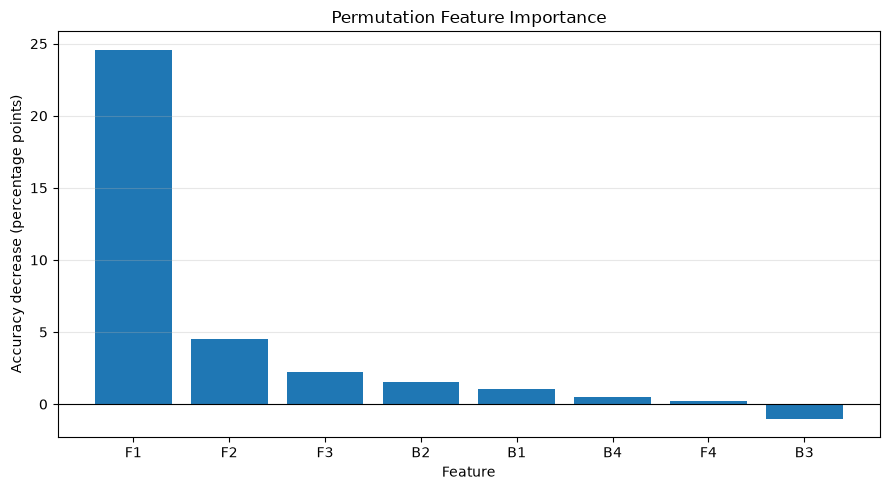

In [13]:
def permutation_feature_importance(
    model, test, features, classes, num_iter=10, random_state=42
):
    rng = np.random.default_rng(random_state)

    X_test = test[features].copy()
    y_test = test['Phoneme'].values

    # Baseline accuracy without shuffling
    baseline_pred = predict_vowel(X_test.values, model, classes)
    baseline_accuracy = accuracy_score(y_test, baseline_pred)

    results = []

    for feature in features:
        accuracy_scores = []

        for _ in range(num_iter):
            # Start from the original test data each time
            X_shuffled = X_test.copy()

            # Shuffle this feature while keeping other features unchanged
            X_shuffled[feature] = rng.permutation(
                X_shuffled[feature].values
            )

            predictions = predict_vowel(
                X_shuffled.values, model, classes
            )

            accuracy_scores.append(
                accuracy_score(y_test, predictions)
            )

        mean_accuracy = np.mean(accuracy_scores)
        mean_drop = baseline_accuracy - mean_accuracy

        results.append({
            'Feature': feature,
            'Mean shuffled accuracy': mean_accuracy,
            'Accuracy drop': mean_drop,
            'Importance (%)': mean_drop * 100,
            'Std. deviation': np.std(accuracy_scores)
        })

    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(
        'Importance (%)', ascending=False
    ).reset_index(drop=True)

    print(f'Baseline accuracy: {baseline_accuracy:.2%}')
    print(f'\nPermutation importance over {num_iter} repetitions:')
    print(results_df.round(4).to_string(index=False))

    # Plot the average accuracy decrease
    plt.figure(figsize=(9, 5))
    plt.bar(
        results_df['Feature'],
        results_df['Importance (%)']
    )
    plt.axhline(0, color='black', linewidth=0.8)
    plt.xlabel('Feature')
    plt.ylabel('Accuracy decrease (percentage points)')
    plt.title('Permutation Feature Importance')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    return results_df


# Train the eight-feature model if you have not already done so
model = train_model(train, classes, features)

# Evaluate feature importance
importance_results = permutation_feature_importance(
    model, test, features, classes, num_iter=10
)

### Task 8

We want to make the model slightly more powerful by modeling the feature vector conditional on both the vowel and gender of speaker, that is $P(x|g,c)$, where $g$ is the gender of the speaker and $c$ is the phoneme label. Show how these models can be used for phoneme classification using marginalization over the gender.

Assume that $P(x|g,c)$ is a multivariate Gaussian and compute the maximum likelihood estimates for the models. Compare the result on the test set with the results in Task 5.

In [14]:
from scipy.special import logsumexp

# ---------------------------------------------
# 1. Train gender-conditioned Gaussian models
# ---------------------------------------------

def train_gender_model(train, classes, features, gender_col='Gender'):

    model = {}

    for c in classes:

        class_data = train[train['Phoneme'] == c]
        class_count = len(class_data)

        model[c] = {
            'prior': class_count / len(train),
            'genders': {}
        }

        for g in class_data[gender_col].dropna().unique():

            data = class_data[
                class_data[gender_col] == g
            ][features].values

            # Maximum likelihood estimates
            mean = np.mean(data, axis=0)
            cov = np.cov(data, rowvar=False, bias=True)

            model[c]['genders'][g] = {
                'mean': mean,
                'cov': cov,
                'prior_gender_given_class': len(data) / class_count
            }

    return model


# ---------------------------------------------
# 2. Predict by marginalizing over gender
# ---------------------------------------------

def predict_vowel_gender(X, model, classes):

    predictions = []

    for x in X:

        class_scores = []

        for c in classes:

            gender_scores = []

            for g, params in model[c]['genders'].items():

                log_likelihood = multivariate_normal.logpdf(
                    x,
                    mean=params['mean'],
                    cov=params['cov']
                )

                log_gender_prior = np.log(
                    params['prior_gender_given_class']
                )

                gender_scores.append(
                    log_likelihood + log_gender_prior
                )

            # Sum over genders in probability space,
            # implemented stably in log space
            log_marginal_likelihood = logsumexp(gender_scores)

            score = (
                log_marginal_likelihood
                + np.log(model[c]['prior'])
            )

            class_scores.append(score)

        predictions.append(classes[np.argmax(class_scores)])

    return np.array(predictions)

Confusion Matrix:
           Predicted ae  Predicted ey  Predicted ux
Actual ae            84            21             0
Actual ey            15            89            10
Actual ux             4            24            24

Accuracy: 0.7269372693726938


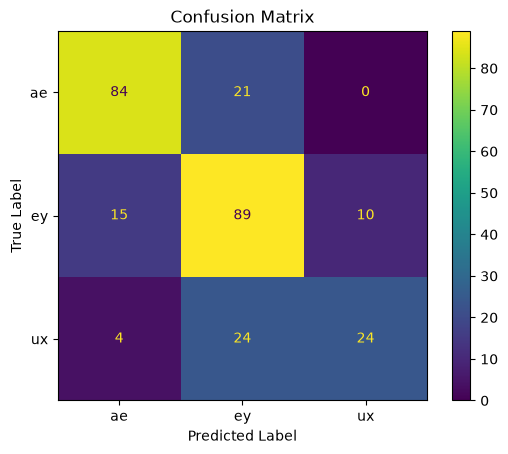

In [15]:


gender_model = train_gender_model(
train, classes, features, gender_col='Gender'
)

X_test = test[features].values
y_test = test['Phoneme'].values

gender_predictions = predict_vowel_gender(
X_test, gender_model, classes
)

evaluate_model(y_test, gender_predictions, classes)
plot_confusion_matrix(y_test, gender_predictions, classes)

In [16]:
# Original model from Task 5
original_model = train_model(train, classes, features)

original_predictions = predict_vowel(
    X_test, original_model, classes
)

print("Task 5: Original Gaussian Bayes model")
evaluate_model(y_test, original_predictions, classes)

print("\nGender-conditioned model")
evaluate_model(y_test, gender_predictions, classes)

print("\nAccuracy comparison:")
print(
    "Task 5:",
    f"{accuracy_score(y_test, original_predictions):.2%}"
)
print(
    "Gender-conditioned:",
    f"{accuracy_score(y_test, gender_predictions):.2%}"
)

Task 5: Original Gaussian Bayes model
Confusion Matrix:
           Predicted ae  Predicted ey  Predicted ux
Actual ae            82            23             0
Actual ey            13            90            11
Actual ux             3            28            21

Accuracy: 0.7121771217712177

Gender-conditioned model
Confusion Matrix:
           Predicted ae  Predicted ey  Predicted ux
Actual ae            84            21             0
Actual ey            15            89            10
Actual ux             4            24            24

Accuracy: 0.7269372693726938

Accuracy comparison:
Task 5: 71.22%
Gender-conditioned: 72.69%


### Task 9

When using Gaussian classifiers we often avoid computing the entire covariance matrix, but instead we only use the diagonal of the matrix. Repeat the results in Task 5 using only diagonal covariance matrices and compare the results.

_For this task, the only change necessary, is the line ```cov = np.diag(np.diag(cov))``` to diagonilize the covariance matrix_

In [17]:
def train_model(train, vowels, features):

    model = {}

    for v in vowels:
        data = train[train['Phoneme'] == v][features].values

        mean = np.mean(data, axis=0)
        cov = np.cov(data, rowvar=False, bias=True)
        prior = len(data) / len(train)

        cov = np.diag(np.diag(cov))
        model[v] = {
            'mean': mean,
            'cov': cov,
            'prior': prior
        }

    return model

features = ['F1', 'F2', 'F3', 'F4']
data = train[train['Phoneme'] == v][features].values


Vowel: ae
Mean: [0.6698604  1.7423804  2.59929494 3.95421828]
Covariance matrix:
 [[0.0105471  0.         0.         0.        ]
 [0.         0.0628065  0.         0.        ]
 [0.         0.         0.06974166 0.        ]
 [0.         0.         0.         0.13707   ]]
Prior probability: 0.31115107913669066

Vowel: ey
Mean: [0.50455191 1.97840056 2.6682647  3.93370995]
Covariance matrix:
 [[0.00600115 0.         0.         0.        ]
 [0.         0.08754451 0.         0.        ]
 [0.         0.         0.08477129 0.        ]
 [0.         0.         0.         0.12678471]]
Prior probability: 0.5089928057553957

Vowel: ux
Mean: [0.38738423 1.78944744 2.51461378 3.8702682 ]
Covariance matrix:
 [[0.00488957 0.         0.         0.        ]
 [0.         0.09384261 0.         0.        ]
 [0.         0.         0.06678    0.        ]
 [0.         0.         0.         0.10432254]]
Prior probability: 0.17985611510791366
Confusion Matrix:
           Predicted ae  Predicted ey  Predicted u

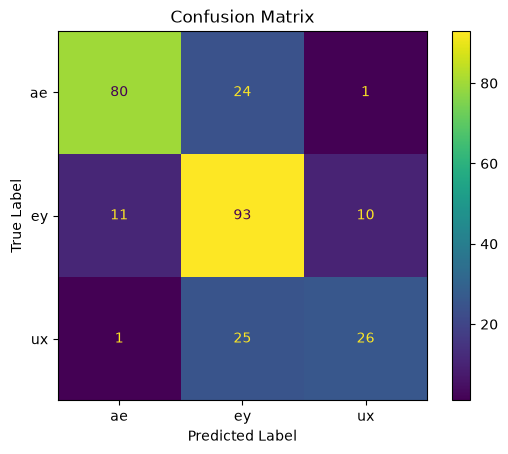

In [18]:
# Choose the classes and features
vowels = ['ae', 'ey', 'ux']

# Train the model using four features
model = train_model(train, vowels, features)

# Print estimated parameters
print_parameters(model, vowels)

# Predict the test labels
X_test = test[features].values
y_test = test['Phoneme'].values

predictions = predict_vowel(X_test, model, vowels)

# Evaluate the classifier
evaluate_model(y_test, predictions, vowels)

# Plot the confusion matrix
plot_confusion_matrix(y_test, predictions, vowels)

_Based on the accuracy output, we see that the accuracy output of the diagonalized cov-matrix is somewhere around $2.2%$ less than when using the full covariance matrix. This makes sense, as the model retrieves a lot more training data._

_However, we greatly reduce the amount of training data, while still keepeing somewhat accurate predictions. That is why I think reducing systems to diagonalized covariance matrices is an often used practice_


## Problem 2: SVMs

In this problem we use the support vector machine (SVM) to build classifiers. We use the same dataset as in Problem 1. It is up to you to select which features to use.

We use the function `sklearn.svm.SVC` from `scikit-learn` in this problem.

An example on how to use the `SVC` is given in http://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC. In short, we do the following (for a linear kernel):
- Instantiate an SVC object: `cls = SVC(kernel='linear')`
- Train the SVM using the feature vector matrix `train_X`, and label vector `train_Y`: `cls.fit(train_X, train_Y)`
- Predict labels on the test set `Test_X` using: `cls.predict(Test_X)`

You can use or adapt the following functions to visualize the SVM decision regions and support vectors in 2D.

In [19]:
import numpy as np
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')

def Plot_SVM_decision_regions(clf: SVC, data: np.array, labels: np.array) -> None:
    '''
    This function is for plotting the decision area of SVM

    Args:
    - clf: SVM model
    - data: Data with two features
    - labels: Corresponding labels of the data
    '''
    x_min, x_max = data[:,0].min() - 0.2, data[:,0].max() + 0.2
    y_min, y_max = data[:,1].min() - 0.2, data[:,1].max() + 0.2
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.002),np.arange(y_min, y_max, 0.002))
    # we need to use the LabelEncoder here to make contourf work
    label_encoder = LabelEncoder()
    integer_encoded = label_encoder.fit_transform(labels)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = label_encoder.transform(Z)
    Z = Z.reshape(xx.shape)
    #Plotting
    plt.figure(figsize=(10,6))
    sns.scatterplot(x = data[:,0], y = data[:,1],hue=labels)
    plt.contourf(xx, yy, Z, cmap=plt.cm.ocean, alpha=0.2)
    plt.legend()
    plt.title('Decision Area of SVM')
    plt.show()

def Plot_Support_Vectors(clf: SVC, data: np.array) -> None:
    '''
    This function is for plotting the support vectors of the SVM model

    Args:
    - clf: SVM model
    - data: Data with two features
    '''
    x_min, x_max = data[:,0].min() - 0.2, data[:,0].max() + 0.2
    y_min, y_max = data[:,1].min() - 0.2, data[:,1].max() + 0.2
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.002),np.arange(y_min, y_max, 0.002))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    # we need to use the LabelEncoder here to make contourf work
    label_encoder = LabelEncoder()
    Z = label_encoder.fit_transform(Z)
    Z = Z.reshape(xx.shape)
    #Plotting
    plt.figure(figsize=(10,6))
    plt.scatter(clf.support_vectors_[:,0], clf.support_vectors_[:,1], c='k',alpha=0.4,label='support vector')
    plt.contourf(xx, yy, Z, cmap=plt.cm.ocean, alpha=0.2)
    plt.legend()
    plt.title('Support Vectors')
    plt.show()

### Task 10

Create a linear SVM with different penalty terms $C=\{0.1, 1, 10\}$ and compare with the results in Problem 1.


--- C = 0.1 (accuracy = 0.5092) ---


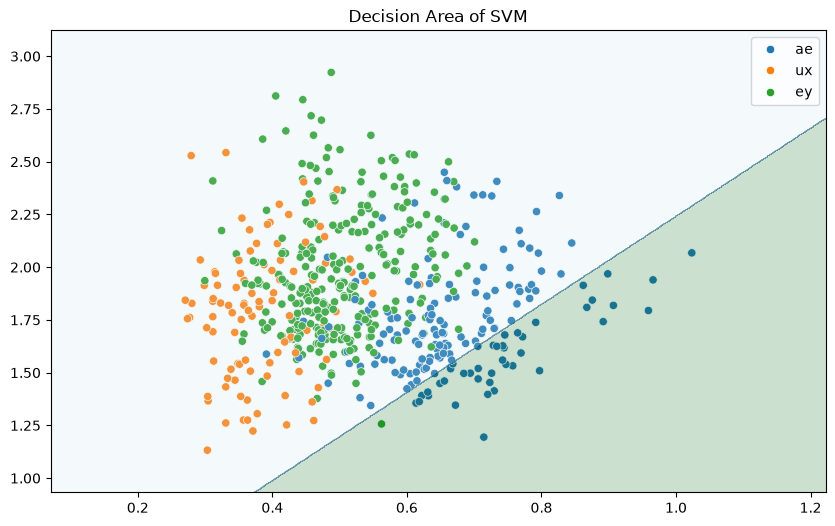


--- C = 1 (accuracy = 0.6790) ---


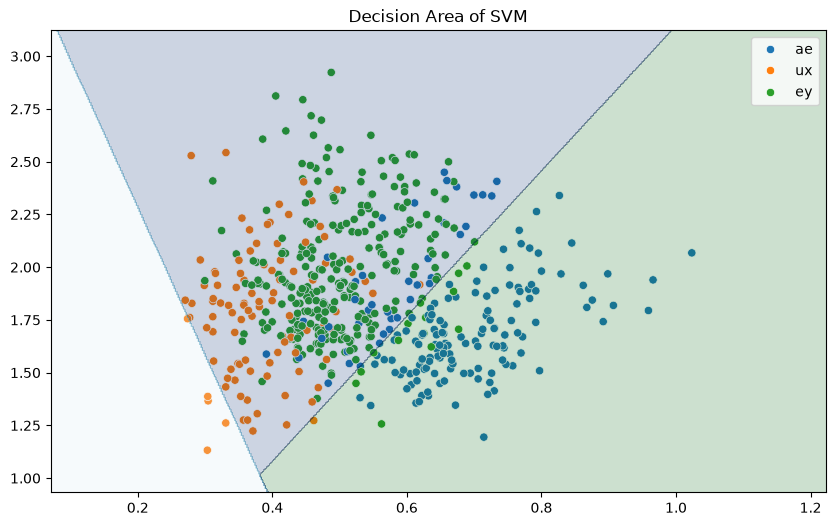


--- C = 10 (accuracy = 0.7528) ---


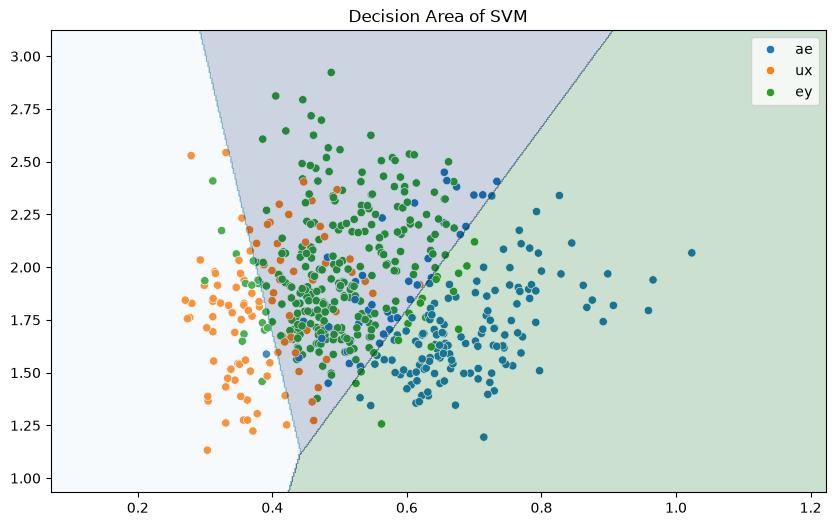


--- C = 100 (accuracy = 0.7528) ---


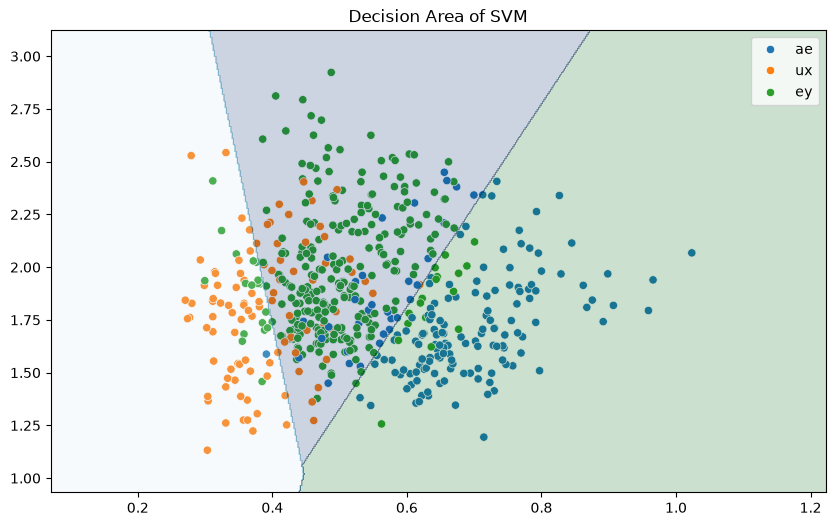

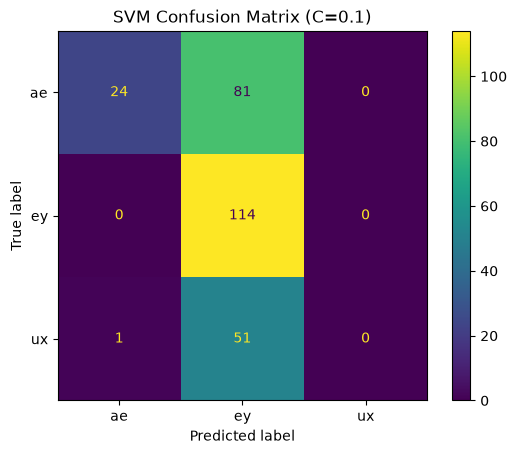

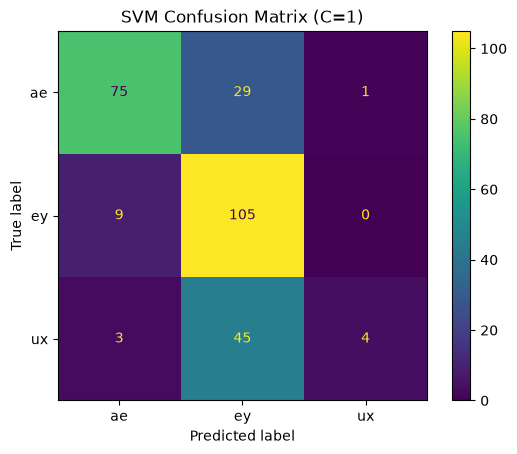

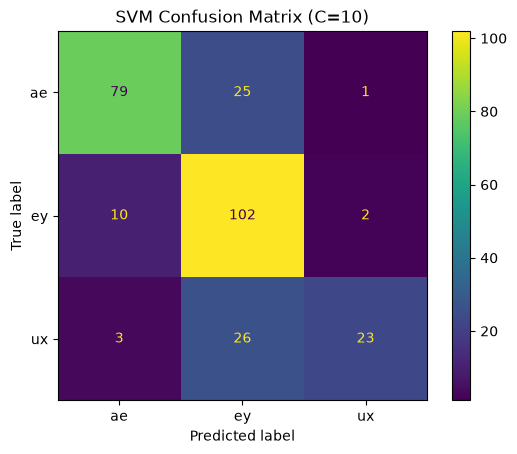

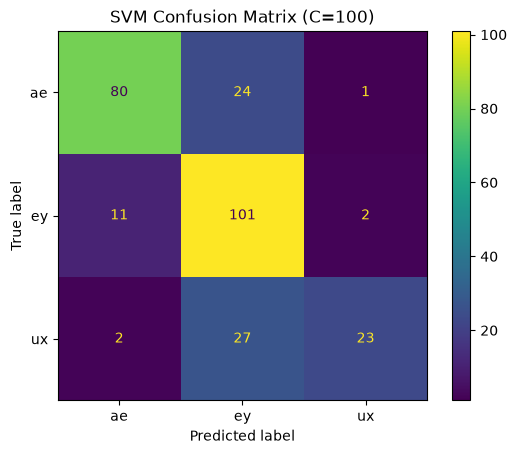

In [20]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# ---------------------------------------------
# Prepare data
# ---------------------------------------------
features_2d = ['F1', 'F2']

train_X = train[features_2d].values
train_Y = train['Phoneme'].values

test_X = test[features_2d].values
test_Y = test['Phoneme'].values

classes = np.unique(train_Y)

# ---------------------------------------------
# Train linear SVMs with different C values
# ---------------------------------------------
C_values = [0.1, 1, 10, 100]
svm_models = {}
svm_results = {}

for C in C_values:
    cls = SVC(kernel='linear', C=C)
    cls.fit(train_X, train_Y)

    predictions = cls.predict(test_X)
    acc = accuracy_score(test_Y, predictions)

    svm_models[C] = cls
    svm_results[C] = {
        'accuracy': acc,
        'predictions': predictions
    }

# ---------------------------------------------
# Plot decision regions for each C
# ---------------------------------------------
for C in C_values:
    print(f"\n--- C = {C} (accuracy = {svm_results[C]['accuracy']:.4f}) ---")
    Plot_SVM_decision_regions(svm_models[C], train_X, train_Y)

# ---------------------------------------------
# Confusion matrices for each C
# ---------------------------------------------
for C in C_values:
    predictions = svm_results[C]['predictions']
    cm = confusion_matrix(test_Y, predictions, labels=classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot()
    plt.title(f'SVM Confusion Matrix (C={C})')
    plt.show()

_The lower the C, the weeker the constraints. This means that as C increases the output should saturate at a level where mistakes are punished, while still allowing some guesswork as the vowels do have some overlap._

_When I added an additional level of C at $C=100$, we see that the accuracy increases by nothing, and that the model must have reached its potential_

### Task 11

Try different kernels ('rbf', 'poly', 'sigmoid') and compare the results. Choose one of the kernels and use different penalty terms $C$. What happens with the performance on the training set when you increase $C$? What happens with the performance on the test set?

# AI decleration

_For this task I have used both ChatGPT and Claude in order to facilitate the given answers. Most of the assignment is a combination of my own work in coding or giving detailed prompts to the aforementioned LLMs, but tasks 7, 8 and 10 introduced new concepts that I was very unfamiliar with, and with a faster moving deadline than expected, I tried to interpret the answer to the best of my ability._